# 🧪 TP3: Supervised Classification — Breast Cancer Wisconsin Diagnostic
### Academic Laboratory Practical Work | Chapter IV: Classification
**Course:** Machine Learning & Statistical Pattern Recognition  
**Environment Support:** Google Colab & VS Code Compatible  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/saoula2026/ml_univ/blob/main/TP3/breast_cancer_dataset/TP3_Breast_Cancer.ipynb)

---

## 🎯 Practical Work Objectives & Syllabus Coverage
In this practical session (**TP3**), we conduct an exhaustive, rigorous empirical and theoretical study of **11 foundational classification algorithms** introduced in **Chapter IV: Classification**:

1. **Logistic Regression** (Binary Cross-Entropy & Logit Link)
2. **Polynomial Logistic Regression** (Non-linear Basis Feature Expansion)
3. **Simple Perceptron** (Rosenblatt's Linear Threshold Unit)
4. **Multi-Layer Perceptron (MLP)** (Feedforward Neural Network with Backpropagation)
5. **Decision Tree with Information Gain (Entropy)** (Shannon Entropy Minimization)
6. **Decision Tree with Gini Impurity** (Variance of Class Distribution)
7. **Random Forest Classifier** (Bootstrap Aggregation & Random Feature Subspaces)
8. **K-Nearest Neighbors ($k$-NN)** (Non-parametric Instance-based Metric Learning)
9. **Gaussian Naive Bayes** (Probabilistic Likelihood with Class-Conditional Independence)
10. **Linear Support Vector Machine (Linear SVM)** (Primal/Dual Margin Maximization)
11. **Non-Linear Support Vector Machine (RBF Kernel SVM)** (Hilbert Space Mapping via Gaussian Kernel)

### Pedagogical Pipeline
* **Section 1: Exploratory Data Analysis (EDA):** Inspect feature topologies, class balances, collinearities, and descriptive distributions.
* **Section 2: Data Preprocessing & Validation Setup:** Collinearity analysis, hold-out stratified splitting, and strict leakage-free standard scaling.
* **Section 3: Model Training, Theoretical Derivations & Full Multi-Metric Evaluation:** For every single classifier, analyze mathematical formulas, train with 5-fold stratified cross-validation, plot side-by-side Confusion Matrices and ROC curves, and compute interactive visualizations.
* **Section 4: Hyperparameter Optimization:** Systematic grid search with cross-validation (`GridSearchCV`) on key models (Random Forest and Support Vector Machine).
* **Section 5: Final Model Comparison & Academic Conclusion:** Quantitative synthesis table with highlighted optima, comparative metric plots, and in-depth analytical conclusions regarding model inductive biases and geometric data structures.

In [1]:
# ==============================================================================
# SECTION 0: Environment Setup & Library Imports
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

# Core scientific computing and data manipulation
import numpy as np
import pandas as pd

# Data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# Set Plotly renderer for universal notebook compatibility (VS Code & Colab)
pio.renderers.default = "notebook_connected"

# Scikit-Learn: Datasets & Validation
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline

# Scikit-Learn: Classification Models
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Scikit-Learn: Performance Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    classification_report
)

# Global plot formatting settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 14

# Set global random state for reproducible experiments
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("✅ All required libraries successfully imported.")
print(f"📊 NumPy Version: {np.__version__}")
print(f"🐼 Pandas Version: {pd.__version__}")

✅ All required libraries successfully imported.
📊 NumPy Version: 2.4.6
🐼 Pandas Version: 3.0.3


## 1. Data Loading & Exploratory Data Analysis (EDA)

The **Breast Cancer Wisconsin (Diagnostic)** dataset is a celebrated medical classification benchmark created by Dr. William H. Wolberg, W. Nick Street, and Olvi L. Mangasarian (1995). 

Features are computed from a digitized image of a fine-needle aspirate (FNA) of a breast mass, describing characteristics of the cell nuclei present in the image:
* **Instances:** 569 patient samples.
* **Attributes:** 30 continuous numeric features representing 10 fundamental morphological metrics computed across three statistics: **Mean**, **Standard Error (SE)**, and **Worst (mean of the three largest values)**:
  1. *Radius* (mean of distances from center to points on the perimeter)
  2. *Texture* (standard deviation of gray-scale values)
  3. *Perimeter*
  4. *Area*
  5. *Smoothness* (local variation in radius lengths)
  6. *Compactness* ($\frac{\text{perimeter}^2}{\text{area}} - 1.0$)
  7. *Concavity* (severity of concave portions of the contour)
  8. *Concave points* (number of concave portions of the contour)
  9. *Symmetry*
  10. *Fractal dimension* ("coastline approximation" - 1)
* **Target Classes:** Binary diagnosis:
  * `0`: **Malignant** (Cancerous / High Clinical Risk)
  * `1`: **Benign** (Non-cancerous / Safe)

In [2]:
# Load the raw dataset from scikit-learn
raw_data = load_breast_cancer(as_frame=True)
df = raw_data.frame.copy()

# Add human-readable target labels
df['diagnosis'] = df['target'].map({0: 'Malignant', 1: 'Benign'})

# Display structural summary
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns (30 features + target + diagnosis label)")
df.head(10)

Dataset Shape: 569 rows, 32 columns (30 features + target + diagnosis label)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant
5,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,0.07613,...,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440,0,Malignant
6,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,0.05742,...,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368,0,Malignant
7,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,0.07451,...,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510,0,Malignant
8,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,0.07389,...,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720,0,Malignant
9,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,0.08243,...,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750,0,Malignant


In [3]:
# Summary information: Data types, memory footprint, and non-null counts
print("--- Dataframe Information ---")
df.info()

print("\n--- Missing Values Audit ---")
missing_counts = df.isnull().sum()
print(f"Total missing values across all cells: {missing_counts.sum()}")

print("\n--- Duplicate Rows Audit ---")
duplicate_count = df.duplicated().sum()
print(f"Total duplicate rows: {duplicate_count}")

--- Dataframe Information ---
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothn

In [4]:
# Descriptive statistical summary of numerical features
df.drop(columns=['target', 'diagnosis']).describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']].head(10)

,mean,std,min,25%,50%,75%,max
mean radius,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


--- Target Class Distribution ---


,Count,Percentage (%)
diagnosis,,
Benign,357,62.74
Malignant,212,37.26


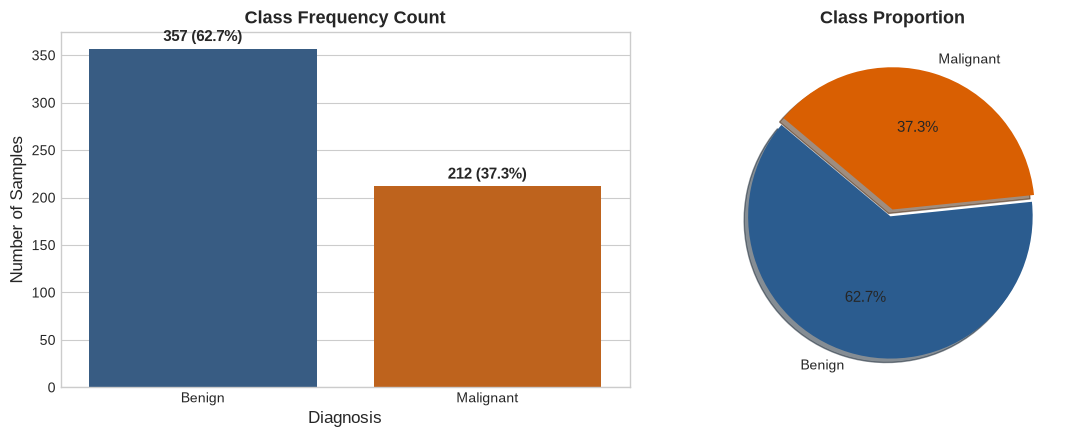

In [5]:
# Target Class Balance Analysis
class_counts = df['diagnosis'].value_counts()
class_percentages = df['diagnosis'].value_counts(normalize=True) * 100

class_summary = pd.DataFrame({
    'Count': class_counts,
    'Percentage (%)': class_percentages.round(2)
})
print("--- Target Class Distribution ---")
display(class_summary)

# Visualizing target distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Countplot
sns.barplot(x=class_summary.index, y=class_summary['Count'], palette=['#2b5c8f', '#d95f02'], ax=axes[0])
axes[0].set_title("Class Frequency Count", fontweight='bold')
axes[0].set_ylabel("Number of Samples")
axes[0].set_xlabel("Diagnosis")
for i, count in enumerate(class_summary['Count']):
    axes[0].text(i, count + 8, f"{count} ({class_percentages.iloc[i]:.1f}%)", ha='center', fontweight='bold')

# Pie chart
axes[1].pie(
    class_counts,
    labels=class_counts.index,
    autopct='%1.1f%%',
    colors=['#2b5c8f', '#d95f02'],
    startangle=140,
    explode=[0.05, 0],
    shadow=True
)
axes[1].set_title("Class Proportion", fontweight='bold')

plt.tight_layout()
plt.show()

In [6]:
# Interactive Exploratory Scatter Plot (Plotly)
fig_eda = px.scatter(
    df,
    x='mean radius',
    y='mean texture',
    color='diagnosis',
    color_discrete_map={'Malignant': '#d95f02', 'Benign': '#2b5c8f'},
    size='mean area',
    hover_data=['mean perimeter', 'mean smoothness', 'mean concavity'],
    title="Interactive EDA: Mean Radius vs. Mean Texture (Bubble Size = Mean Area)",
    labels={'mean radius': 'Mean Radius (μm)', 'mean texture': 'Mean Texture'},
    template='plotly_white',
    marginal_x='box',
    marginal_y='box'
)
fig_eda.update_layout(width=900, height=550)
fig_eda.show()

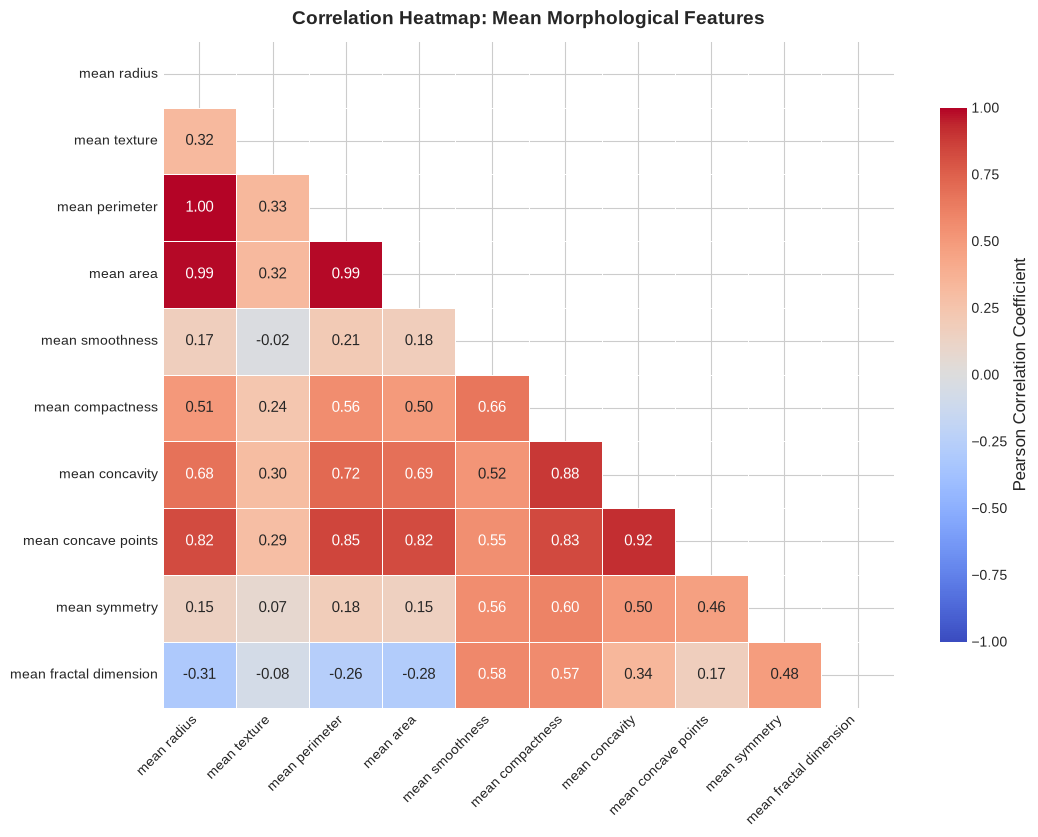

In [7]:
# Feature Correlation Heatmap
features_only = df.drop(columns=['target', 'diagnosis'])
corr_matrix = features_only.corr()

# Focus on the 10 'mean' morphological features for clear academic presentation
mean_features = [col for col in features_only.columns if col.startswith('mean ')]
mean_corr = features_only[mean_features].corr()

plt.figure(figsize=(11, 8.5))
mask = np.triu(np.ones_like(mean_corr, dtype=bool))
sns.heatmap(
    mean_corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient"}
)
plt.title("Correlation Heatmap: Mean Morphological Features", fontsize=14, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

> [!NOTE]
> ### 🔍 Critical EDA & Multicollinearity Findings:
> 1. **Extreme Collinearities:** Several feature pairs exhibit near-perfect linear dependencies ($r > 0.95$):
>    * `mean radius` $\\leftrightarrow$ `mean perimeter` ($r = 0.998$)
>    * `mean radius` $\\leftrightarrow$ `mean area` ($r = 0.987$)
>    * `mean perimeter` $\\leftrightarrow$ `mean area` ($r = 0.987$)
>    * `mean concavity` $\\leftrightarrow$ `mean concave points` ($r = 0.921$)
> 2. **Implications for Modeling:**
>    * **Linear Models (Logistic Regression, Linear SVM, Perceptron):** Multicollinearity does not harm predictive accuracy, but it inflates the variance of estimated coefficients, making individual feature weights unstable unless $L_2$ regularization is enforced.
>    * **Naive Bayes:** Strongly violates the naive class-conditional independence assumption $P(X|Y) = \\prod P(X_j|Y)$.
>    * **Tree-based Models (Decision Trees, Random Forest):** Invariant to monotonic collinearity, as splits evaluate one dimension at a time.

## 2. Data Preprocessing

### 2.1 Multicollinearity Analysis & Feature Retention Strategy
In standard data engineering pipelines, we can drop redundant features when the pairwise correlation exceeds a strict threshold (e.g., $|r| > 0.95$). Below we compute and display all such pairs. For our pedagogical benchmarking in this TP, we retain the full 30-feature feature set to empirically test how regularized models, distance metrics, and naive independence models behave when confronted with real-world correlated data.

### 2.2 Target Encoding
* Label `0`: **Malignant** (Tumor with aggressive cancer characteristics)
* Label `1`: **Benign** (Non-cancerous tissue)

### 2.3 Hold-out Validation Strategy (Section 9 of Chapter IV)
According to **Section 9 of Chapter IV**, supervised evaluation requires an unbiased hold-out partition:
$$\\mathcal{D} = \\mathcal{D}_{\\text{train}} \\cup \\mathcal{D}_{\\text{test}}, \\quad \\mathcal{D}_{\\text{train}} \\cap \\mathcal{D}_{\\text{test}} = \\emptyset$$
* **Stratified Sampling:** Because the class distribution is imbalanced (62.7% benign vs. 37.3% malignant), simple random sampling risks sampling bias. Stratified splitting (`stratify=y`) ensures that both train (80%) and test (20%) partitions strictly preserve the exact class ratio.

### 2.4 Feature Scaling (`StandardScaler`) & Leakage Prevention
Features in this dataset exhibit starkly different scales: `mean area` spans $[143.5, 2501.0]$ while `mean smoothness` spans $[0.05, 0.16]$.
Without normalization:
* **Distance-based algorithms ($k$-NN):** The Euclidean metric $\\sqrt{\\sum (x_i - x_j)^2}$ would be completely dominated by `area`.
* **Margin & Gradient algorithms (SVM, Perceptron, Logistic Regression, MLP):** Spherical contour level curves accelerate gradient convergence and ensure equal regularization penalty across weights.

**Data Leakage Prevention Rule:**
$$\\mu_{\\text{train}} = \\frac{1}{N_{\\text{train}}} \\sum x_i, \\quad \\sigma_{\\text{train}} = \\sqrt{\\frac{1}{N_{\\text{train}}} \\sum (x_i - \\mu_{\\text{train}})^2}$$
$$X_{\\text{train, scaled}} = \\frac{X_{\\text{train}} - \\mu_{\\text{train}}}{\\sigma_{\\text{train}}}, \\quad X_{\\text{test, scaled}} = \\frac{X_{\\text{test}} - \\mu_{\\text{train}}}{\\sigma_{\\text{train}}}$$
The scaler is **fitted exclusively on the training set** and applied to both train and test sets.

In [8]:
# 1. Inspect highly correlated pairs (threshold > 0.95)
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        col1 = corr_matrix.columns[i]
        col2 = corr_matrix.columns[j]
        val = corr_matrix.iloc[i, j]
        if abs(val) > 0.95:
            high_corr_pairs.append((col1, col2, round(val, 4)))

df_high_corr = pd.DataFrame(high_corr_pairs, columns=['Feature 1', 'Feature 2', 'Pearson r'])
print(f"Total feature pairs with |r| > 0.95: {len(df_high_corr)}")
display(df_high_corr.head(8))

Total feature pairs with |r| > 0.95: 15


,Feature 1,Feature 2,Pearson r
0,mean radius,mean perimeter,0.9979
1,mean radius,mean area,0.9874
2,mean radius,worst radius,0.9695
3,mean radius,worst perimeter,0.9651
4,mean perimeter,mean area,0.9865
5,mean perimeter,worst radius,0.9695
6,mean perimeter,worst perimeter,0.9704
7,mean area,worst radius,0.9627


In [9]:
# 2. Extract feature matrix X and target vector y
X = df.drop(columns=['target', 'diagnosis'])
y = df['target']

# Target encoding dictionary
label_mapping = {0: 'Malignant', 1: 'Benign'}
print("Target Encoding Mapping:", label_mapping)

# 3. Train-Test Split (80% Train, 20% Test) with Stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training feature matrix shape: {X_train.shape} ({X_train.shape[0]} samples)")
print(f"Testing feature matrix shape:  {X_test.shape} ({X_test.shape[0]} samples)")

# Verify stratified proportions
train_dist = y_train.value_counts(normalize=True).round(4) * 100
test_dist = y_test.value_counts(normalize=True).round(4) * 100
print(f"Train Class Proportions: Benign={train_dist[1]}%, Malignant={train_dist[0]}%")
print(f"Test Class Proportions:  Benign={test_dist[1]}%, Malignant={test_dist[0]}%")

Target Encoding Mapping: {0: 'Malignant', 1: 'Benign'}
Training feature matrix shape: (455, 30) (455 samples)
Testing feature matrix shape:  (114, 30) (114 samples)
Train Class Proportions: Benign=62.63999999999999%, Malignant=37.36%
Test Class Proportions:  Benign=63.160000000000004%, Malignant=36.84%


In [10]:
# 4. Feature Scaling (StandardScaler) strictly avoiding data leakage
scaler = StandardScaler()

# Fit on training set only, then transform both
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Verify empirical scaling properties: mean ~ 0, std ~ 1
print("Scaled X_train - Mean across features (first 5):", np.round(X_train_scaled.mean(axis=0)[:5], 4))
print("Scaled X_train - Std across features  (first 5):", np.round(X_train_scaled.std(axis=0)[:5], 4))
print("Scaled X_test  - Mean across features (first 5):", np.round(X_test_scaled.mean(axis=0)[:5], 4))

Scaled X_train - Mean across features (first 5): [-0.  0. -0. -0.  0.]
Scaled X_train - Std across features  (first 5): [1. 1. 1. 1. 1.]
Scaled X_test  - Mean across features (first 5): [0.0858 0.048  0.0852 0.092  0.0716]


## 3. Classification Models (Training, Theory, Formulas & Full Evaluation)

### Evaluation Metrics Framework (Chapter IV, Section 9)
For binary classification with Positive class ($P$) and Negative class ($N$), let the Confusion Matrix be defined as:

| | **Predicted Negative ($\hat{y}=0$)** | **Predicted Positive ($\hat{y}=1$)** |
|---|:---:|:---:|
| **Actual Negative ($y=0$, Malignant)** | **True Negative ($TN$)** | **False Positive ($FP$, Type I Error)** |
| **Actual Positive ($y=1$, Benign)** | **False Negative ($FN$, Type II Error)** | **True Positive ($TP$)** |

The exact mathematical formulas evaluated for every model are:

$$\\text{Accuracy} = \\frac{TP + TN}{TP + FP + TN + FN}$$

$$\\text{Precision (Positive Predictive Value)} = \\frac{TP}{TP + FP}$$

$$\\text{Recall (Sensitivity / True Positive Rate)} = \\frac{TP}{TP + FN}$$

$$\\text{Specificity (True Negative Rate)} = \\frac{TN}{TN + FP}$$

$$\\text{F1-Score} = 2 \\cdot \\frac{\\text{Precision} \\cdot \\text{Recall}}{\\text{Precision} + \\text{Recall}} = \\frac{2 \\cdot TP}{2 \\cdot TP + FP + FN}$$

$$\\text{ROC Curve (Receiver Operating Characteristic):} \\quad \\text{Plot of } \\text{TPR} = \\frac{TP}{TP + FN} \\quad \\text{vs.} \\quad \\text{FPR} = \\frac{FP}{FP + TN} = 1 - \\text{Specificity}$$

$$\\text{ROC-AUC} = \\int_{0}^{1} \\text{TPR}(\\text{FPR}) \\, d(\\text{FPR})$$

In [11]:
# Master Evaluation Framework Function
results_summary = []

def evaluate_and_plot_model(
    model_name,
    model,
    X_train_s,
    y_train,
    X_test_s,
    y_test,
    is_perceptron=False
):
    """
    Trains a model, executes 5-fold stratified cross-validation, prints full metrics,
    and visualizes the Confusion Matrix and ROC curve side-by-side.
    """
    # 1. 5-Fold Stratified Cross-Validation on Training Data
    cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_scores = cross_val_score(model, X_train_s, y_train, cv=cv_strategy, scoring='accuracy')
    cv_mean = cv_scores.mean()
    cv_std = cv_scores.std()

    # 2. Fit model on full training set
    model.fit(X_train_s, y_train)

    # 3. Predictions on Train and Test sets
    y_train_pred = model.predict(X_train_s)
    y_test_pred = model.predict(X_test_s)

    # 4. Probability / Decision function for ROC curve
    if is_perceptron:
        # Perceptron lacks predict_proba; calibrate decision function via Sigmoid
        scores = model.decision_function(X_test_s)
        y_test_prob = 1.0 / (1.0 + np.exp(-scores))
    else:
        y_test_prob = model.predict_proba(X_test_s)[:, 1]

    # 5. Metric Calculations
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    
    cm = confusion_matrix(y_test, y_test_pred)
    tn, fp, fn, tp = cm.ravel()

    precision = precision_score(y_test, y_test_pred, zero_division=0)
    recall = recall_score(y_test, y_test_pred, zero_division=0)
    f1 = f1_score(y_test, y_test_pred, zero_division=0)
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    auc = roc_auc_score(y_test, y_test_prob)

    # Append to global benchmark registry
    record = {
        'Model': model_name,
        'Train Accuracy': round(train_acc, 4),
        'Test Accuracy': round(test_acc, 4),
        '5-Fold CV Mean Accuracy': round(cv_mean, 4),
        'Precision': round(precision, 4),
        'Recall': round(recall, 4),
        'F1-Score': round(f1, 4),
        'Specificity': round(specificity, 4),
        'ROC-AUC': round(auc, 4)
    }
    results_summary.append(record)

    # 6. Console Report
    print(f"================================================================================")
    print(f"📊 PERFORMANCE REPORT: {model_name.upper()}")
    print(f"================================================================================")
    print(f"• Training Set Accuracy:           {train_acc:.4f} ({train_acc*100:.2f}%)")
    print(f"• 5-Fold Stratified CV Accuracy:   {cv_mean:.4f} ± {cv_std:.4f}")
    print(f"• Test Set Accuracy:               {test_acc:.4f} ({test_acc*100:.2f}%)")
    print(f"• Precision (PPV):                 {precision:.4f}")
    print(f"• Recall / Sensitivity (TPR):      {recall:.4f}")
    print(f"• Specificity (TNR):               {specificity:.4f}")
    print(f"• F1-Score:                        {f1:.4f}")
    print(f"• ROC-AUC Score:                   {auc:.4f}")
    print(f"• Detailed Breakdown (TN={tn}, FP={fp}, FN={fn}, TP={tp})")

    # 7. Side-by-Side Visualizations (Matplotlib / Seaborn)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

    # Left: Confusion Matrix Heatmap
    cm_labels = np.array([
        [f"TN\n{tn}\n({tn/len(y_test)*100:.1f}%)", f"FP\n{fp}\n({fp/len(y_test)*100:.1f}%)"],
        [f"FN\n{fn}\n({fn/len(y_test)*100:.1f}%)", f"TP\n{tp}\n({tp/len(y_test)*100:.1f}%)"]
    ])
    sns.heatmap(
        cm,
        annot=cm_labels,
        fmt="",
        cmap="Blues",
        cbar=False,
        ax=axes[0],
        xticklabels=['Pred: Malignant (0)', 'Pred: Benign (1)'],
        yticklabels=['True: Malignant (0)', 'True: Benign (1)']
    )
    axes[0].set_title(f"Confusion Matrix — {model_name}", fontweight='bold', pad=10)
    axes[0].set_xlabel("Predicted Class", fontweight='bold')
    axes[0].set_ylabel("True Class", fontweight='bold')

    # Right: ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_test_prob)
    axes[1].plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'{model_name} (AUC = {auc:.4f})')
    axes[1].plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Random Chance (AUC = 0.5000)')
    axes[1].set_xlim([-0.02, 1.02])
    axes[1].set_ylim([-0.02, 1.05])
    axes[1].set_xlabel('False Positive Rate (1 - Specificity)', fontweight='bold')
    axes[1].set_ylabel('True Positive Rate (Sensitivity)', fontweight='bold')
    axes[1].set_title(f'ROC Curve — {model_name}', fontweight='bold', pad=10)
    axes[1].legend(loc="lower right", frameon=True)

    plt.tight_layout()
    plt.show()

    return record, y_test_prob

### 3.1 Logistic Regression

#### Theoretical Foundations & Formulas (Chapter IV)
Logistic Regression models the posterior probability of the binary class $Y \\in \\{0, 1\\}$ conditioned on input features $x \\in \\mathbb{R}^d$ using the **Sigmoid (Logistic) activation function**:
$$P(Y=1|X=x) = \\sigma(z) = \\frac{1}{1 + e^{-z}}, \\quad \\text{where } z = w^T x + b = \\sum_{j=1}^d w_j x_j + b$$

The **Odds Ratio** and corresponding linear **Logit (Log-Odds)** are:
$$\\text{Odds} = \\frac{P(Y=1|x)}{1 - P(Y=1|x)} = e^{w^T x + b} \\implies \\ln\\left(\\frac{P(Y=1|x)}{1 - P(Y=1|x)}\\right) = w^T x + b$$

The parameters $w$ and $b$ are estimated by minimizing the **Binary Cross-Entropy (Log-Loss)** with $L_2$ regularization:
$$J(w, b) = -\\frac{1}{N} \\sum_{i=1}^N \\left[ y_i \\ln(\\sigma(w^T x_i + b)) + (1 - y_i) \\ln(1 - \\sigma(w^T x_i + b)) \\right] + \\frac{1}{2C} \\|w\\|_2^2$$

📊 PERFORMANCE REPORT: LOGISTIC REGRESSION
• Training Set Accuracy:           0.9890 (98.90%)
• 5-Fold Stratified CV Accuracy:   0.9780 ± 0.0098
• Test Set Accuracy:               0.9825 (98.25%)
• Precision (PPV):                 0.9861
• Recall / Sensitivity (TPR):      0.9861
• Specificity (TNR):               0.9762
• F1-Score:                        0.9861
• ROC-AUC Score:                   0.9954
• Detailed Breakdown (TN=41, FP=1, FN=1, TP=71)


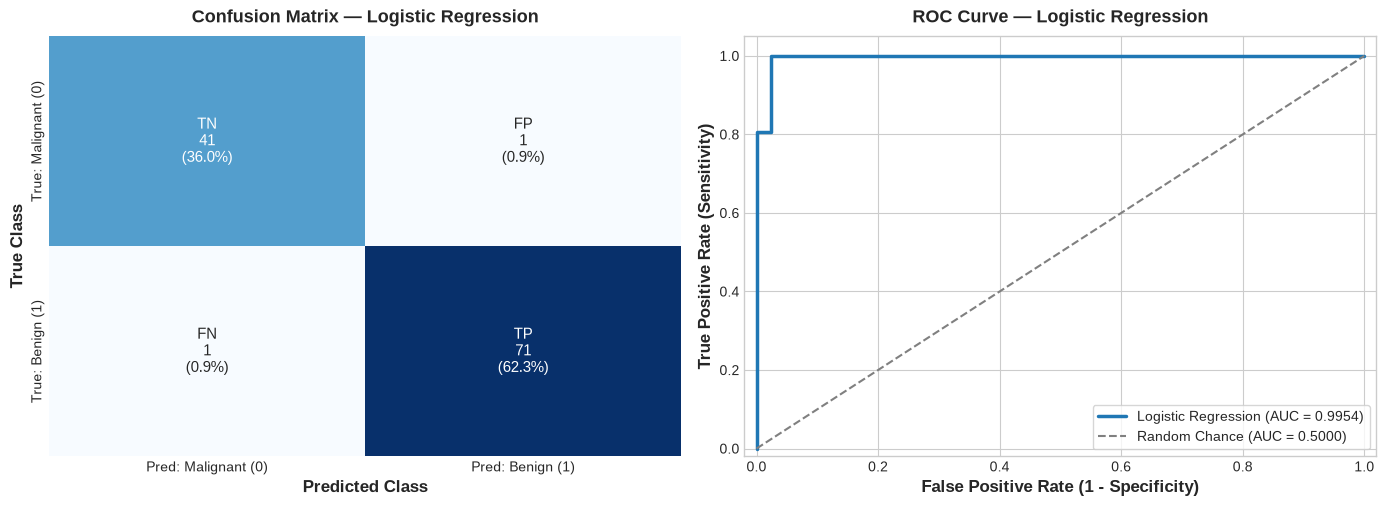

In [12]:
# 3.1 Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
_, lr_probs = evaluate_and_plot_model(
    "Logistic Regression",
    lr_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.2 Polynomial Logistic Regression

#### Theoretical Foundations & Formulas (Chapter IV)
When classes are not strictly linearly separable, we map the original feature vector $x \\in \\mathbb{R}^d$ into a higher-dimensional polynomial feature space $\\phi(x) \\in \\mathbb{R}^M$ using degree-$2$ basis expansion:
$$\\phi(x) = \\left[ 1, \\, x_1, \\, x_2, \\dots, x_d, \\, x_1^2, \\, x_1 x_2, \\dots, x_d^2 \\right]^T$$

The decision boundary equation:
$$w^T \\phi(x) + b = 0$$
yields a quadratic hypersurface in the original input space, capable of capturing non-linear interactions between morphological features.

📊 PERFORMANCE REPORT: POLYNOMIAL LOGISTIC REGRESSION
• Training Set Accuracy:           0.9978 (99.78%)
• 5-Fold Stratified CV Accuracy:   0.9604 ± 0.0204
• Test Set Accuracy:               0.9298 (92.98%)
• Precision (PPV):                 0.9706
• Recall / Sensitivity (TPR):      0.9167
• Specificity (TNR):               0.9524
• F1-Score:                        0.9429
• ROC-AUC Score:                   0.9878
• Detailed Breakdown (TN=40, FP=2, FN=6, TP=66)


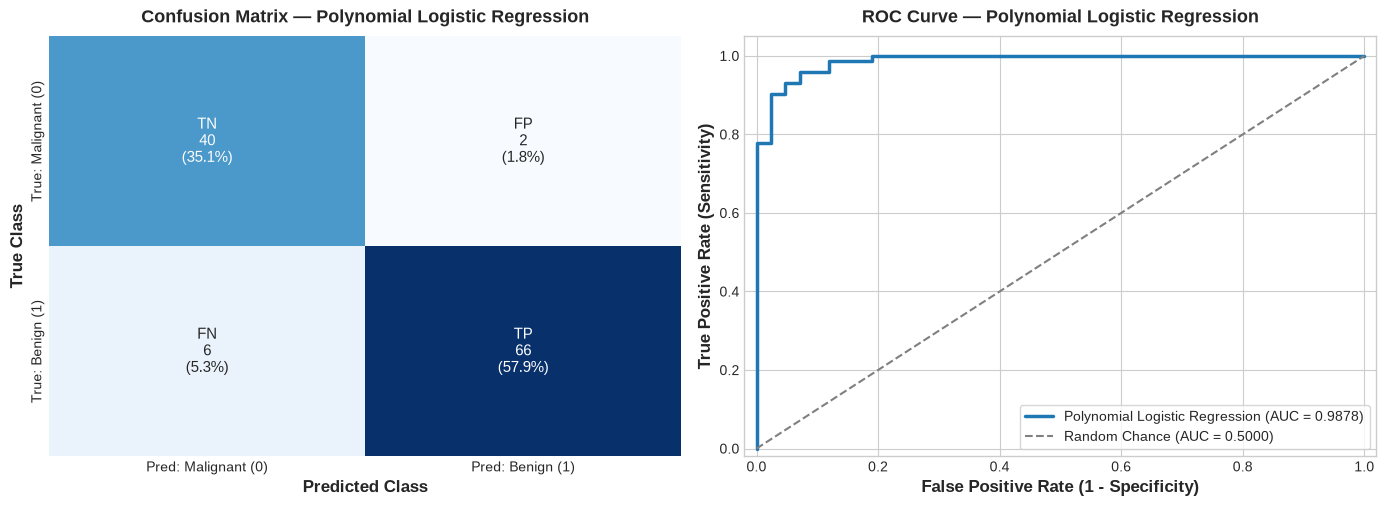

In [13]:
# 3.2 Polynomial Logistic Regression (Degree = 2)
poly_lr_model = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('log_reg', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

_, poly_lr_probs = evaluate_and_plot_model(
    "Polynomial Logistic Regression",
    poly_lr_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.3 Simple Perceptron

#### Theoretical Foundations & Formulas (Chapter IV)
Introduced by Frank Rosenblatt (1958), the **Perceptron** is the simplest artificial neuron and linear threshold unit. It computes the net sum:
$$z = w^T x + b = \\sum_{j=1}^d w_j x_j + b$$

and applies the non-differentiable **Heaviside Step Activation Function**:
$$\\hat{y} = f(z) = \\begin{cases} 1 & \\text{if } z \\ge 0 \\\\ 0 & \\text{if } z < 0 \\end{cases}$$

**Weight Update Rule:** For every misclassified training sample $(x_i, y_i)$:
$$w \\leftarrow w + \\eta (y_i - \\hat{y}_i) x_i, \\quad b \\leftarrow b + \\eta (y_i - \\hat{y}_i)$$
where $\\eta \\in (0, 1]$ is the learning rate.

*Perceptron Convergence Theorem:* If the training data is linearly separable, the Perceptron is guaranteed to converge in a finite number of steps. If not separable, the algorithm oscillates without converging.

📊 PERFORMANCE REPORT: SIMPLE PERCEPTRON
• Training Set Accuracy:           0.9846 (98.46%)
• 5-Fold Stratified CV Accuracy:   0.9604 ± 0.0112
• Test Set Accuracy:               0.9561 (95.61%)
• Precision (PPV):                 0.9855
• Recall / Sensitivity (TPR):      0.9444
• Specificity (TNR):               0.9762
• F1-Score:                        0.9645
• ROC-AUC Score:                   0.9940
• Detailed Breakdown (TN=41, FP=1, FN=4, TP=68)


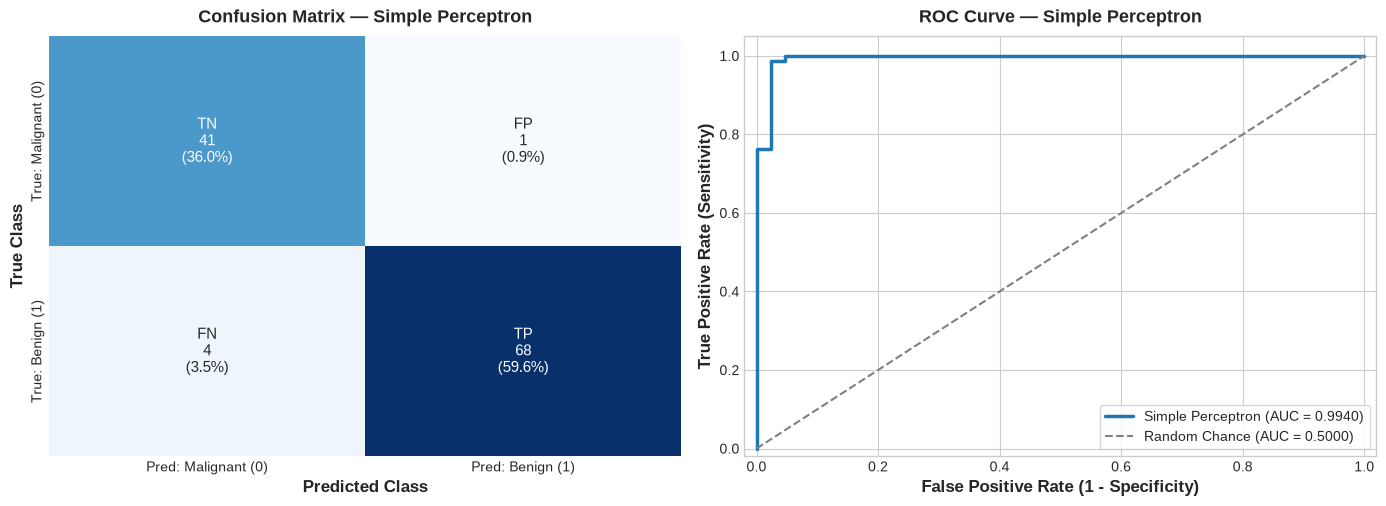

In [14]:
# 3.3 Simple Perceptron
perceptron_model = Perceptron(max_iter=1000, tol=1e-3, random_state=RANDOM_STATE)
_, perc_probs = evaluate_and_plot_model(
    "Simple Perceptron",
    perceptron_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test,
    is_perceptron=True
)

### 3.4 Multi-Layer Perceptron (MLP)

#### Theoretical Foundations & Formulas (Chapter IV)
The **Multi-Layer Perceptron (MLP)** overcomes the linear separability limitation of the single Perceptron by stacking multiple fully-connected hidden layers parameterized by weight matrices $W^{(l)}$ and bias vectors $b^{(l)}$.

**Forward Propagation:**
$$a^{(0)} = x$$
$$z^{(l)} = W^{(l)} a^{(l-1)} + b^{(l)}, \\quad a^{(l)} = g(z^{(l)}) \\quad \\text{for } l = 1, \\dots, L-1$$
$$\\hat{y} = \\sigma(z^{(L)}) = \\frac{1}{1 + e^{-z^{(L)}}}$$

where $g(z) = \\max(0, z)$ is the **Rectified Linear Unit (ReLU)** activation function.

**Backpropagation via the Chain Rule:**
The network parameters are optimized via gradient descent (Adam optimizer) by computing error deltas:
$$\\delta^{(L)} = \\frac{\\partial \\mathcal{L}}{\\partial z^{(L)}} = \\hat{y} - y$$
$$\\delta^{(l)} = \\left( (W^{(l+1)})^T \\delta^{(l+1)} \\right) \\odot g'(z^{(l)})$$
$$\\frac{\\partial \\mathcal{L}}{\\partial W^{(l)}} = \\delta^{(l)} (a^{(l-1)})^T, \\quad \\frac{\\partial \\mathcal{L}}{\\partial b^{(l)}} = \\delta^{(l)}$$

📊 PERFORMANCE REPORT: MULTI-LAYER PERCEPTRON (MLP)
• Training Set Accuracy:           1.0000 (100.00%)
• 5-Fold Stratified CV Accuracy:   0.9692 ± 0.0082
• Test Set Accuracy:               0.9649 (96.49%)
• Precision (PPV):                 0.9857
• Recall / Sensitivity (TPR):      0.9583
• Specificity (TNR):               0.9762
• F1-Score:                        0.9718
• ROC-AUC Score:                   0.9937
• Detailed Breakdown (TN=41, FP=1, FN=3, TP=69)


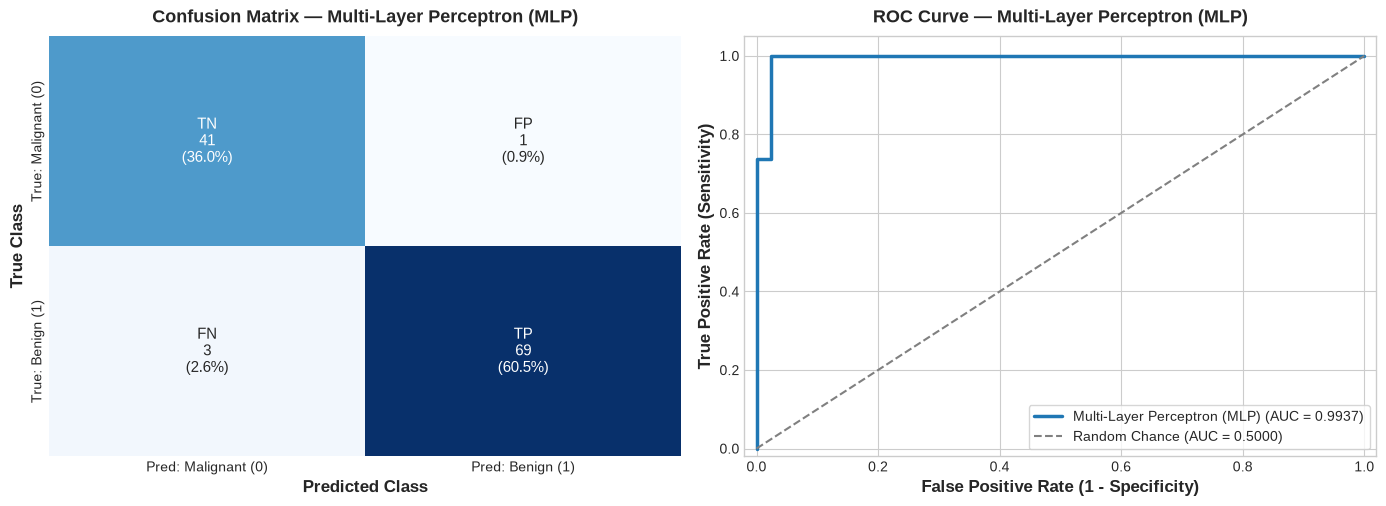

In [15]:
# 3.4 Multi-Layer Perceptron (MLP Classifier)
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=RANDOM_STATE
)

_, mlp_probs = evaluate_and_plot_model(
    "Multi-Layer Perceptron (MLP)",
    mlp_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.5 Decision Tree (Information Gain / Entropy)

#### Theoretical Foundations & Formulas (Chapter IV)
Decision Trees recursively partition the feature space into axis-aligned hyper-rectangles. When using the **Entropy** criterion (ID3 / C4.5 algorithm), split selection maximizes **Information Gain ($IG$)**.

**Shannon Entropy of Node $S$:**
$$H(S) = - \\sum_{c=1}^C p_c \\log_2(p_c)$$
where $p_c$ is the empirical proportion of samples belonging to class $c$ in node $S$. For binary classification:
$$H(S) = - p_0 \\log_2(p_0) - p_1 \\log_2(p_1)$$

**Information Gain ($IG$) for candidate split on attribute $A$:**
$$IG(S, A) = H(S) - \\sum_{v \\in \\text{children}} \\frac{|S_v|}{|S|} H(S_v)$$
The split maximizing $IG(S, A)$ is greedily chosen at each node.

📊 PERFORMANCE REPORT: DECISION TREE (ENTROPY)
• Training Set Accuracy:           0.9670 (96.70%)
• 5-Fold Stratified CV Accuracy:   0.9319 ± 0.0235
• Test Set Accuracy:               0.9474 (94.74%)
• Precision (PPV):                 0.9459
• Recall / Sensitivity (TPR):      0.9722
• Specificity (TNR):               0.9048
• F1-Score:                        0.9589
• ROC-AUC Score:                   0.9448
• Detailed Breakdown (TN=38, FP=4, FN=2, TP=70)


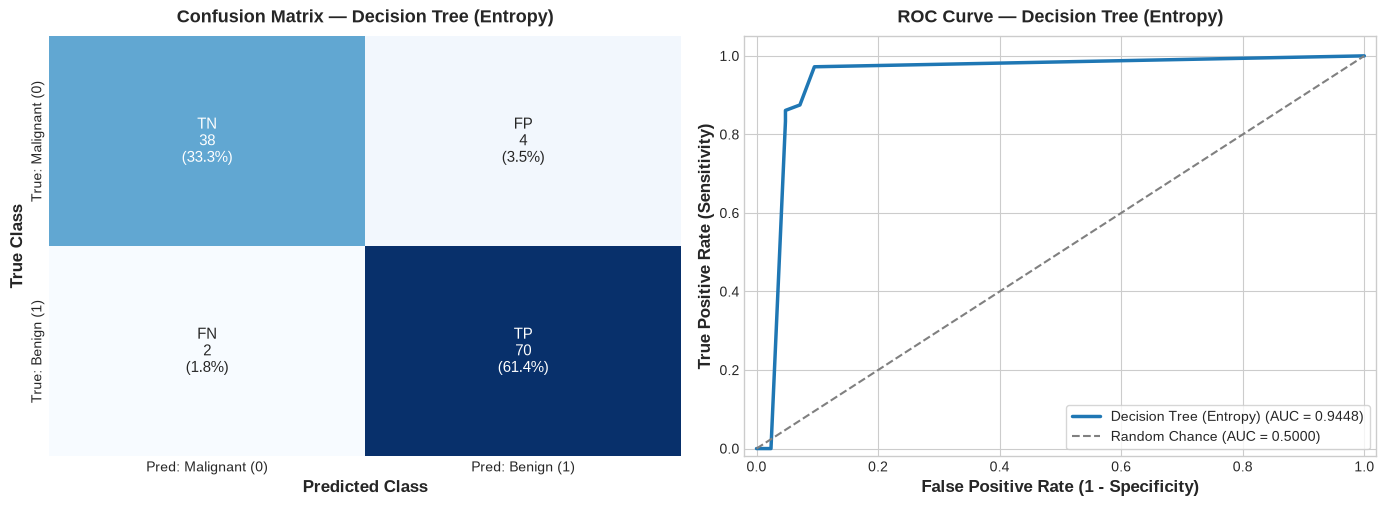

In [16]:
# 3.5 Decision Tree (Entropy, max_depth=3)
dt_entropy_model = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=3,
    random_state=RANDOM_STATE
)

_, dt_entropy_probs = evaluate_and_plot_model(
    "Decision Tree (Entropy)",
    dt_entropy_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

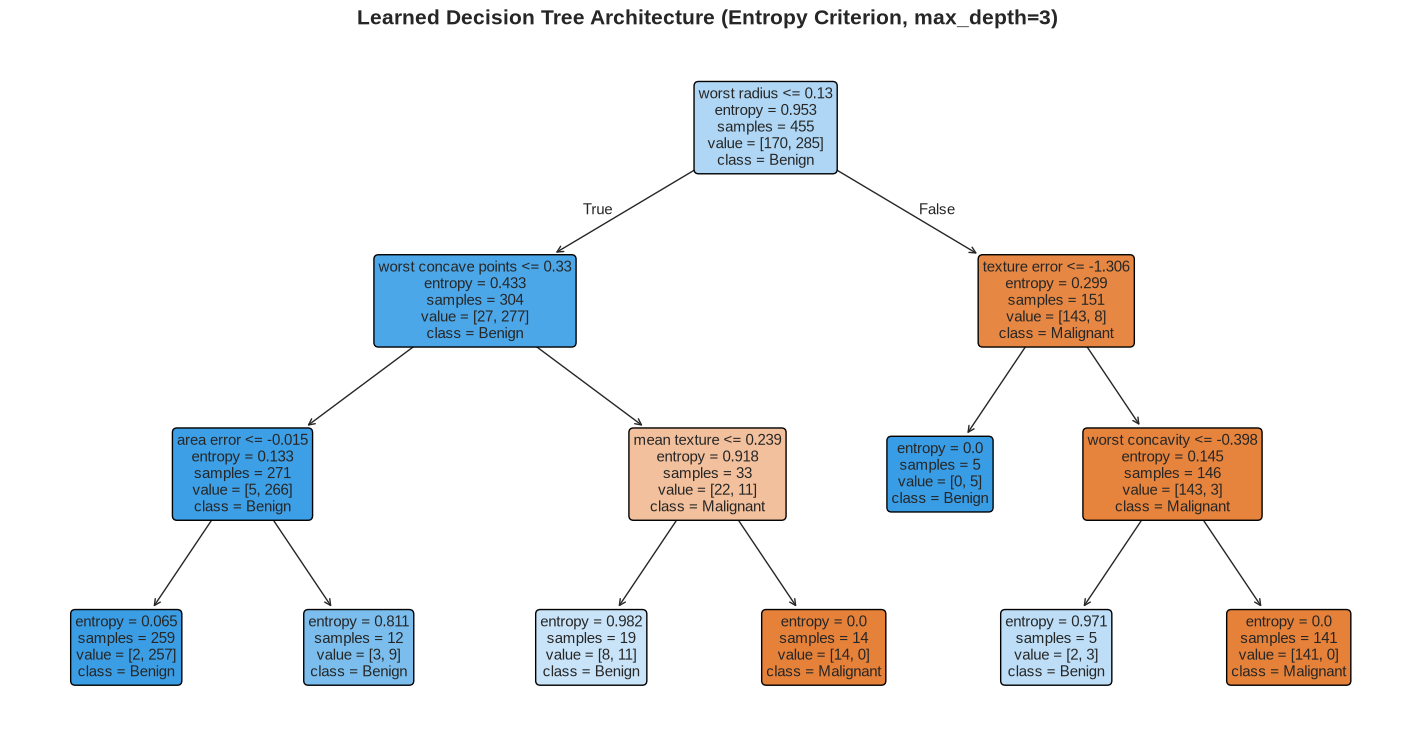

In [17]:
# Visualizing Learned Decision Tree Rules (Entropy)
plt.figure(figsize=(18, 9))
plot_tree(
    dt_entropy_model,
    feature_names=X.columns,
    class_names=['Malignant', 'Benign'],
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("Learned Decision Tree Architecture (Entropy Criterion, max_depth=3)", fontsize=15, fontweight='bold', pad=12)
plt.show()

### 3.6 Decision Tree (Gini Impurity)

#### Theoretical Foundations & Formulas (Chapter IV)
The CART (Classification and Regression Trees) algorithm measures node impurity using **Gini Impurity**:
$$I_G(S) = 1 - \\sum_{c=1}^C p_c^2$$

For binary classification:
$$I_G(S) = 1 - (p_0^2 + p_1^2) = 2 p_0 p_1$$

**Gini Reduction (Gini Gain):**
$$\\Delta I_G(S, A) = I_G(S) - \\sum_{v \\in \\text{children}} \\frac{|S_v|}{|S|} I_G(S_v)$$

*Gini vs. Entropy:* Gini impurity does not involve computing logarithms $\\log_2(p)$, making it computationally faster while yielding virtually identical split choices in practice.

📊 PERFORMANCE REPORT: DECISION TREE (GINI)
• Training Set Accuracy:           0.9758 (97.58%)
• 5-Fold Stratified CV Accuracy:   0.9253 ± 0.0082
• Test Set Accuracy:               0.9386 (93.86%)
• Precision (PPV):                 0.9452
• Recall / Sensitivity (TPR):      0.9583
• Specificity (TNR):               0.9048
• F1-Score:                        0.9517
• ROC-AUC Score:                   0.9446
• Detailed Breakdown (TN=38, FP=4, FN=3, TP=69)


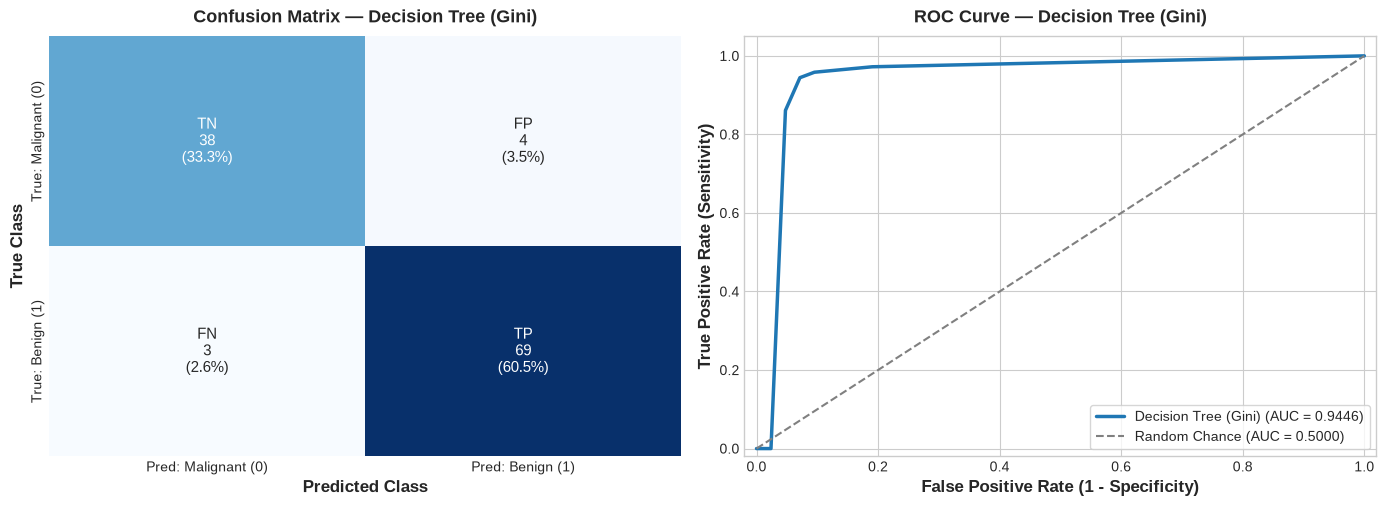

In [18]:
# 3.6 Decision Tree (Gini Impurity, max_depth=3)
dt_gini_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=RANDOM_STATE
)

_, dt_gini_probs = evaluate_and_plot_model(
    "Decision Tree (Gini)",
    dt_gini_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

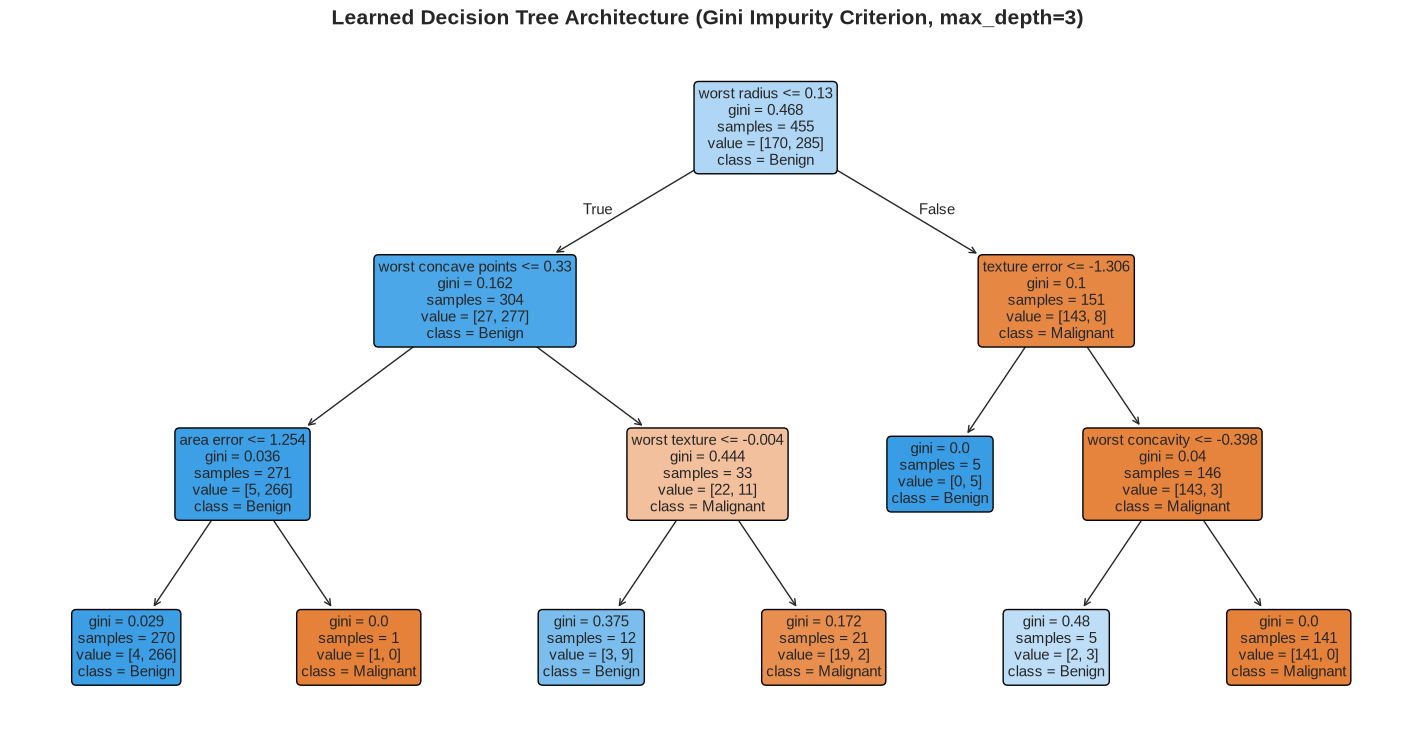

In [19]:
# Visualizing Learned Decision Tree Rules (Gini Impurity)
plt.figure(figsize=(18, 9))
plot_tree(
    dt_gini_model,
    feature_names=X.columns,
    class_names=['Malignant', 'Benign'],
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("Learned Decision Tree Architecture (Gini Impurity Criterion, max_depth=3)", fontsize=15, fontweight='bold', pad=12)
plt.show()

### 3.7 Random Forest Classifier

#### Theoretical Foundations & Formulas (Chapter IV)
**Random Forest** is an ensemble meta-estimator that fits $B$ randomized, decorrelated decision trees using **Bootstrap Aggregation (Bagging)** and **Random Feature Subspace Sampling**:

1. **Bootstrap Sampling:** Draw $B$ random subsets $\\mathcal{D}^{*1}, \\dots, \\mathcal{D}^{*B}$ of size $N$ with replacement from $\\mathcal{D}_{\\text{train}}$ (roughly $63.2\\%$ unique samples per tree).
2. **Feature Subspace Selection:** At each split, evaluate only a random subset of $m$ features:
   $$m = \\lfloor \\sqrt{d} \\rfloor$$
3. **Aggregation / Majority Voting:**
   $$\\hat{y} = \\text{mode}\\left\\{ h_1(x), h_2(x), \\dots, h_B(x) \\right\\}, \\quad P(Y=1|x) = \\frac{1}{B} \\sum_{b=1}^B P_b(Y=1|x)$$

**Variance Reduction Theorem:**
If each tree has variance $\\sigma^2$ and the average pairwise tree correlation is $\\rho$, the ensemble variance is:
$$\\text{Var}(\\bar{h}) = \\rho \\sigma^2 + \\frac{1 - \\rho}{B} \\sigma^2$$
Random feature selection minimizes $\\rho$, driving ensemble variance down as $B \\to \\infty$ without increasing individual tree bias.

📊 PERFORMANCE REPORT: RANDOM FOREST
• Training Set Accuracy:           1.0000 (100.00%)
• 5-Fold Stratified CV Accuracy:   0.9626 ± 0.0179
• Test Set Accuracy:               0.9561 (95.61%)
• Precision (PPV):                 0.9589
• Recall / Sensitivity (TPR):      0.9722
• Specificity (TNR):               0.9286
• F1-Score:                        0.9655
• ROC-AUC Score:                   0.9939
• Detailed Breakdown (TN=39, FP=3, FN=2, TP=70)


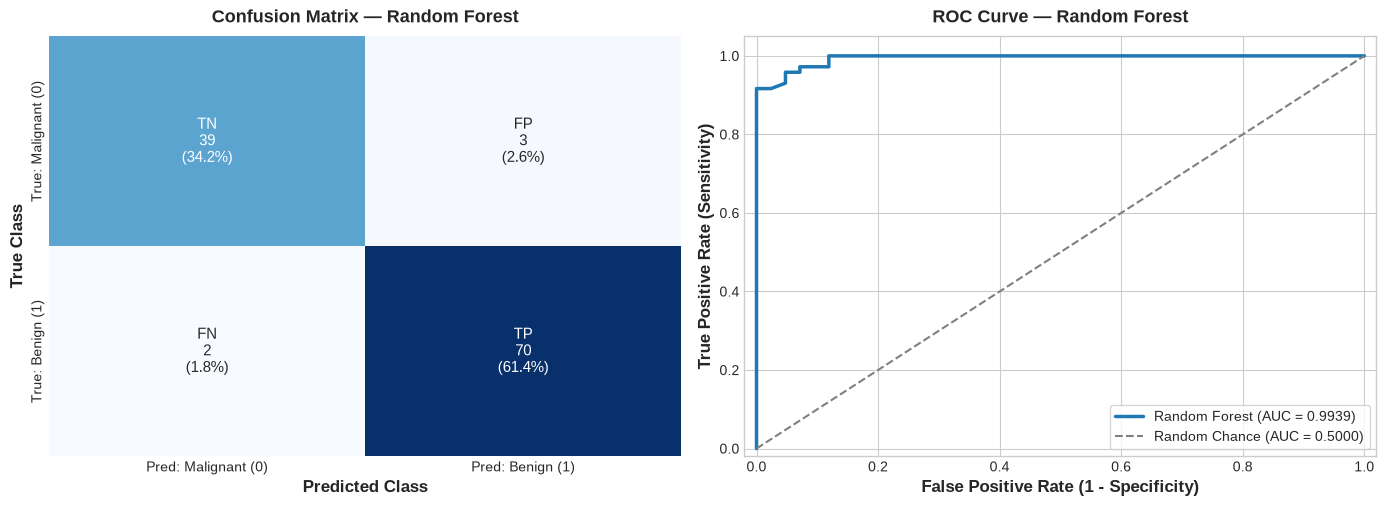

In [20]:
# 3.7 Random Forest Classifier (100 Trees)
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE
)

_, rf_probs = evaluate_and_plot_model(
    "Random Forest",
    rf_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.8 K-Nearest Neighbors ($k$-NN)

#### Theoretical Foundations & Formulas (Chapter IV)
$k$-NN is a non-parametric, memory-based **lazy learning algorithm**. It memorizes all training exemplars and makes local predictions by computing distances to query sample $x$:

**Euclidean Distance Metric in $\\mathbb{R}^d$:**
$$d(x, x') = \\|x - x'\\|_2 = \\sqrt{\\sum_{j=1}^d (x_j - x'_j)^2}$$

Let $\\mathcal{N}_k(x)$ denote the $k$ training points closest to $x$. The posterior probability and predicted class are:
$$P(Y=c|x) = \\frac{1}{k} \\sum_{i \\in \\mathcal{N}_k(x)} \\mathbb{I}(y_i = c)$$
$$\\hat{y} = \\arg\\max_{c} \\sum_{i \\in \\mathcal{N}_k(x)} \\mathbb{I}(y_i = c)$$

*Curse of Dimensionality:* In high dimensions ($d=30$), Euclidean distances become sparse and equidistant unless properly scaled.

📊 PERFORMANCE REPORT: K-NEAREST NEIGHBORS (K-NN)
• Training Set Accuracy:           0.9736 (97.36%)
• 5-Fold Stratified CV Accuracy:   0.9604 ± 0.0112
• Test Set Accuracy:               0.9561 (95.61%)
• Precision (PPV):                 0.9589
• Recall / Sensitivity (TPR):      0.9722
• Specificity (TNR):               0.9286
• F1-Score:                        0.9655
• ROC-AUC Score:                   0.9788
• Detailed Breakdown (TN=39, FP=3, FN=2, TP=70)


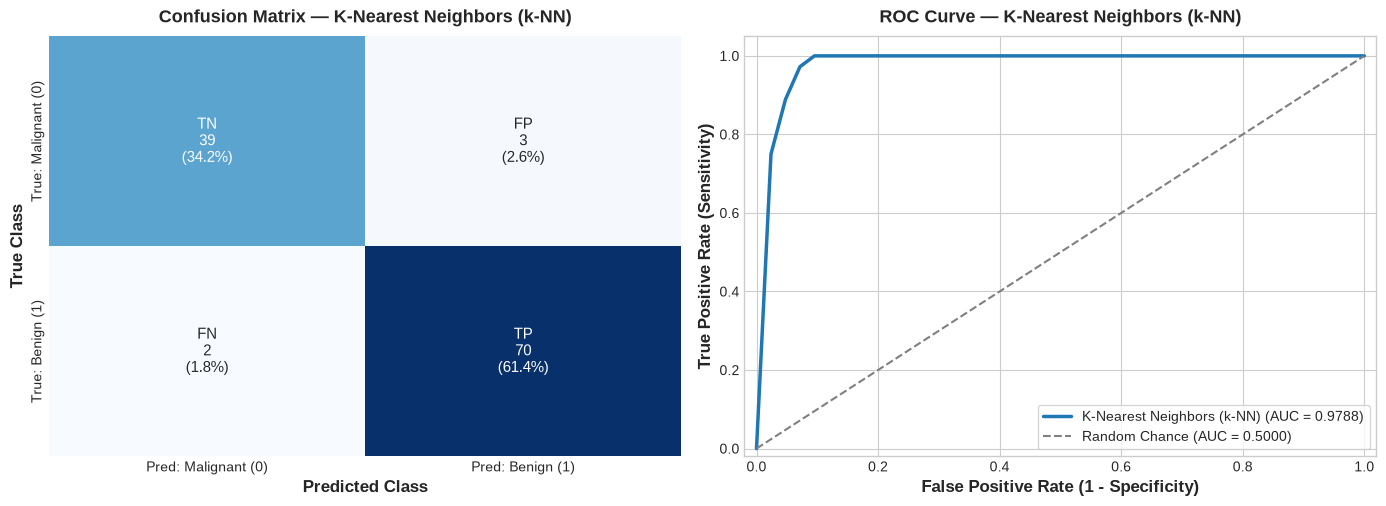

In [21]:
# 3.8 K-Nearest Neighbors (k=5, metric='euclidean')
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric='euclidean'
)

_, knn_probs = evaluate_and_plot_model(
    "K-Nearest Neighbors (k-NN)",
    knn_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.9 Gaussian Naive Bayes

#### Theoretical Foundations & Formulas (Chapter IV)
Gaussian Naive Bayes applies **Bayes' Theorem** combined with the strong ("naive") assumption of **class-conditional feature independence**:

$$P(Y=c|X) = \\frac{P(Y=c) \\, P(X|Y=c)}{P(X)} = \\frac{P(Y=c) \\prod_{j=1}^d P(X_j|Y=c)}{\\sum_{k} P(Y=k) \\prod_{j=1}^d P(X_j|Y=k)}$$

Each continuous feature $X_j$ is modeled as a univariate Gaussian distribution conditioned on class $c$:
$$P(X_j|Y=c) = \\frac{1}{\\sqrt{2 \\pi \\sigma_{jc}^2}} \\exp\\left( - \\frac{(x_j - \\mu_{jc})^2}{2 \\sigma_{jc}^2} \\right)$$

**Decision Rule (Maximum A Posteriori - MAP):**
$$\\hat{y} = \\arg\\max_{c} \\left[ \\ln P(Y=c) + \\sum_{j=1}^d \\ln P(X_j|Y=c) \\right]$$

📊 PERFORMANCE REPORT: GAUSSIAN NAIVE BAYES
• Training Set Accuracy:           0.9385 (93.85%)
• 5-Fold Stratified CV Accuracy:   0.9341 ± 0.0287
• Test Set Accuracy:               0.9298 (92.98%)
• Precision (PPV):                 0.9444
• Recall / Sensitivity (TPR):      0.9444
• Specificity (TNR):               0.9048
• F1-Score:                        0.9444
• ROC-AUC Score:                   0.9868
• Detailed Breakdown (TN=38, FP=4, FN=4, TP=68)


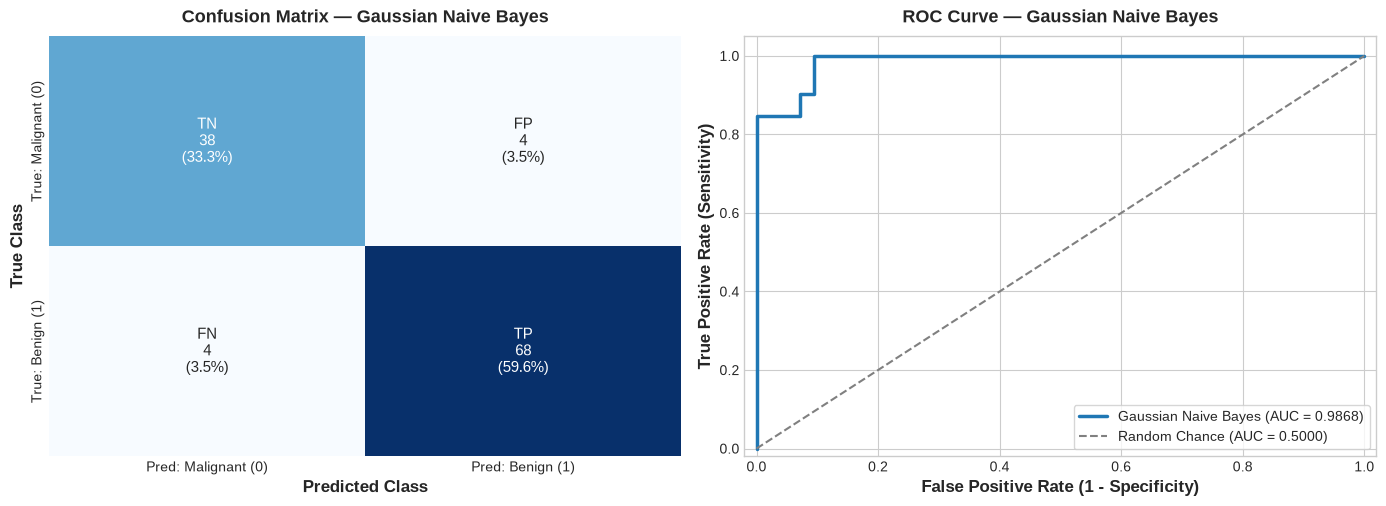

In [22]:
# 3.9 Gaussian Naive Bayes
gnb_model = GaussianNB()

_, gnb_probs = evaluate_and_plot_model(
    "Gaussian Naive Bayes",
    gnb_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.10 Linear Support Vector Machine (Linear SVM)

#### Theoretical Foundations & Formulas (Chapter IV)
Support Vector Machines aim to discover the optimal separating hyperplane that maximizes the geometric **margin** $\\gamma$ between two classes:
$$\\gamma = \\frac{2}{\\|w\\|_2}$$

**Primal Soft-Margin Optimization Problem:**
$$\\min_{w, b, \\xi} \\frac{1}{2} \\|w\\|_2^2 + C \\sum_{i=1}^N \\xi_i$$
$$\\text{subject to } y_i (w^T x_i + b) \\ge 1 - \\xi_i, \\quad \\xi_i \\ge 0 \\quad \\forall i$$
where $\\xi_i$ are slack variables permitting margin violations, and $C > 0$ balances margin width against misclassification penalties.

**Dual Formulation via Lagrange Multipliers $\\alpha_i$:**
$$\\max_{\\alpha} \\sum_{i=1}^N \\alpha_i - \\frac{1}{2} \\sum_{i=1}^N \\sum_{j=1}^N \\alpha_i \\alpha_j y_i y_j (x_i^T x_j)$$
$$\\text{s.t. } 0 \\le \\alpha_i \\le C, \\quad \\sum_{i=1}^N \\alpha_i y_i = 0$$

📊 PERFORMANCE REPORT: LINEAR SVM
• Training Set Accuracy:           0.9912 (99.12%)
• 5-Fold Stratified CV Accuracy:   0.9648 ± 0.0162
• Test Set Accuracy:               0.9737 (97.37%)
• Precision (PPV):                 0.9859
• Recall / Sensitivity (TPR):      0.9722
• Specificity (TNR):               0.9762
• F1-Score:                        0.9790
• ROC-AUC Score:                   0.9964
• Detailed Breakdown (TN=41, FP=1, FN=2, TP=70)


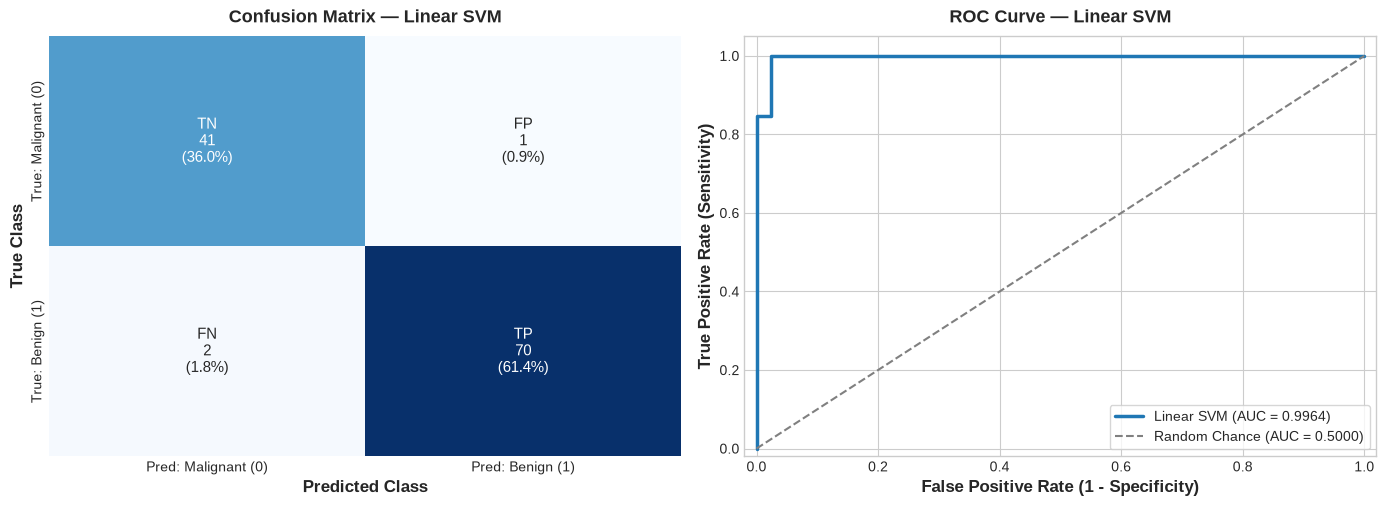

In [23]:
# 3.10 Linear Support Vector Machine
linear_svm_model = SVC(
    kernel='linear',
    probability=True,
    random_state=RANDOM_STATE
)

_, linear_svm_probs = evaluate_and_plot_model(
    "Linear SVM",
    linear_svm_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.11 Non-Linear Support Vector Machine (RBF Kernel SVM)

#### Theoretical Foundations & Formulas (Chapter IV)
The **Kernel Trick** enables SVMs to construct non-linear decision boundaries without explicitly computing transformations $\\phi(x)$ into high-dimensional space:
$$K(x_i, x_j) = \\langle \\phi(x_i), \\phi(x_j) \\rangle$$

The **Radial Basis Function (RBF / Gaussian) Kernel** implicitly projects samples into an infinite-dimensional Hilbert space:
$$K(x_i, x_j) = \\exp\\left( - \\gamma \\|x_i - x_j\\|^2 \\right), \\quad \\gamma = \\frac{1}{2 \\sigma^2} > 0$$

The resulting dual decision function depends only on the **Support Vectors** (samples with $\\alpha_i > 0$):
$$f(x) = \\text{sign}\\left( \\sum_{i \\in \\text{SV}} \\alpha_i y_i \\exp\\left(-\\gamma \\|x_i - x\\|^2\\right) + b \\right)$$

📊 PERFORMANCE REPORT: NON-LINEAR SVM (RBF)
• Training Set Accuracy:           0.9824 (98.24%)
• 5-Fold Stratified CV Accuracy:   0.9670 ± 0.0155
• Test Set Accuracy:               0.9825 (98.25%)
• Precision (PPV):                 0.9861
• Recall / Sensitivity (TPR):      0.9861
• Specificity (TNR):               0.9762
• F1-Score:                        0.9861
• ROC-AUC Score:                   0.9950
• Detailed Breakdown (TN=41, FP=1, FN=1, TP=71)


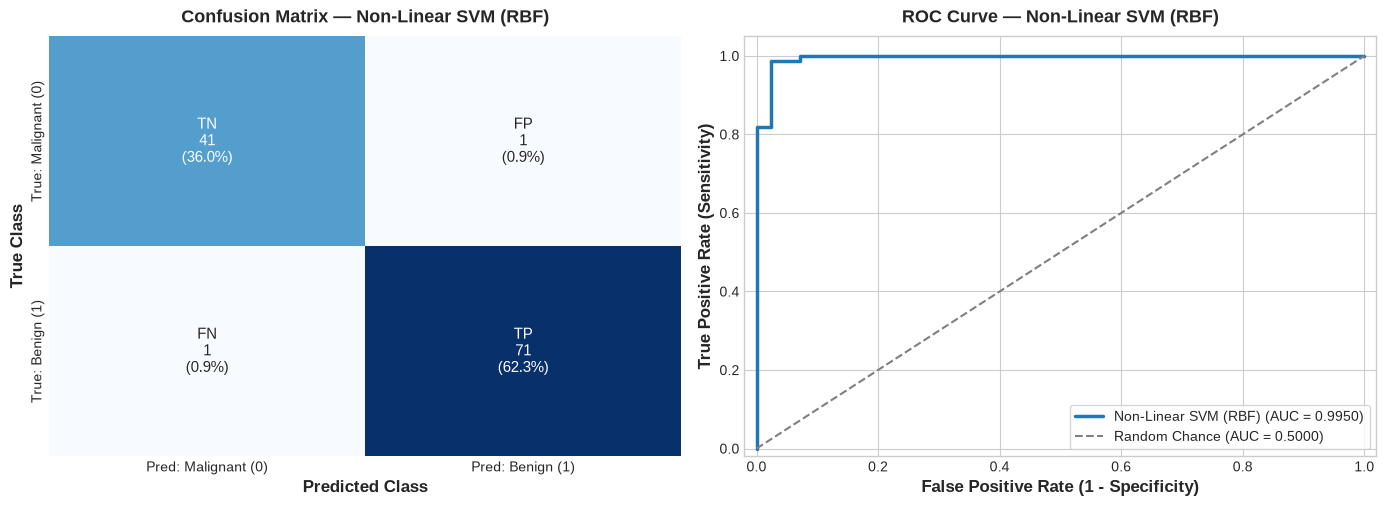

In [24]:
# 3.11 Non-Linear SVM (RBF Kernel)
rbf_svm_model = SVC(
    kernel='rbf',
    probability=True,
    random_state=RANDOM_STATE
)

_, rbf_svm_probs = evaluate_and_plot_model(
    "Non-Linear SVM (RBF)",
    rbf_svm_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

In [25]:
# Interactive Multi-Model ROC Curve Comparison (Plotly)
fig_roc = go.Figure()

models_for_roc = [
    ("Logistic Regression", lr_probs, "#1f77b4"),
    ("Polynomial LR", poly_lr_probs, "#aec7e8"),
    ("Simple Perceptron", perc_probs, "#ff7f0e"),
    ("MLP Classifier", mlp_probs, "#2ca02c"),
    ("Decision Tree (Gini)", dt_gini_probs, "#d62728"),
    ("Random Forest", rf_probs, "#9467bd"),
    ("k-NN (k=5)", knn_probs, "#8c564b"),
    ("Gaussian NB", gnb_probs, "#e377c2"),
    ("Linear SVM", linear_svm_probs, "#7f7f7f"),
    ("RBF SVM", rbf_svm_probs, "#bcbd22")
]

for name, probs, color in models_for_roc:
    fpr_m, tpr_m, _ = roc_curve(y_test, probs)
    auc_m = roc_auc_score(y_test, probs)
    fig_roc.add_trace(go.Scatter(
        x=fpr_m,
        y=tpr_m,
        mode='lines',
        name=f"{name} (AUC={auc_m:.3f})",
        line=dict(color=color, width=2)
    ))

fig_roc.add_trace(go.Scatter(
    x=[0, 1],
    y=[0, 1],
    mode='lines',
    name='Chance (AUC=0.500)',
    line=dict(color='black', width=1.5, dash='dash')
))

fig_roc.update_layout(
    title="Interactive Multi-Model ROC Curves Comparison (Breast Cancer Dataset)",
    xaxis_title="False Positive Rate (1 - Specificity)",
    yaxis_title="True Positive Rate (Recall / Sensitivity)",
    width=920,
    height=600,
    template="plotly_white",
    legend=dict(x=0.58, y=0.08, bgcolor='rgba(255,255,255,0.85)')
)
fig_roc.show()

## 4. Hyperparameter Optimization (`GridSearchCV` — Section 10)

According to **Section 10 of Chapter IV**, manual trial of hyperparameters is suboptimal and prone to overfitting. **Grid Search Cross-Validation (`GridSearchCV`)** evaluates the exhaustive Cartesian product of specified hyperparameter candidates using $K$-Fold cross-validation on the training set:

$$\\theta^* = \\arg\\max_{\\theta \\in \\Theta} \\frac{1}{K} \\sum_{k=1}^K \\text{Score}\\left( f_{\\theta, \\mathcal{D}_{\\text{train}}^{(-k)}}, \\mathcal{D}_{\\text{val}}^{(k)} \\right)$$

Below we optimize two pivotal models:
1. **Random Forest Classifier:** Tuning tree depth `max_depth` and ensemble capacity `n_estimators`.
2. **Support Vector Classifier (SVC):** Tuning margin regularization penalty `C`, kernel choice `kernel`, and kernel bandwidth `gamma`.

In [26]:
# 4.1 Hyperparameter Tuning for Random Forest
print("--- Grid Search: Random Forest Classifier ---")
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 3, 5, 8],
    'min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid_rf,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring='accuracy',
    n_jobs=-1
)
rf_grid.fit(X_train_scaled, y_train)

print(f"Optimal Hyperparameters: {rf_grid.best_params_}")
print(f"Best 5-Fold CV Accuracy: {rf_grid.best_score_:.4f}")

# Evaluate best estimator on holdout test set
best_rf = rf_grid.best_estimator_
rf_test_acc = best_rf.score(X_test_scaled, y_test)
print(f"Hold-out Test Accuracy with Optimized RF: {rf_test_acc:.4f} ({rf_test_acc*100:.2f}%)")

--- Grid Search: Random Forest Classifier ---


Optimal Hyperparameters: {'max_depth': 8, 'min_samples_split': 2, 'n_estimators': 100}
Best 5-Fold CV Accuracy: 0.9648
Hold-out Test Accuracy with Optimized RF: 0.9561 (95.61%)


In [27]:
# 4.2 Hyperparameter Tuning for Support Vector Classifier (SVC)
print("--- Grid Search: Support Vector Machine (SVC) ---")
param_grid_svc = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto', 0.01, 0.1]
}

svc_grid = GridSearchCV(
    estimator=SVC(probability=True, random_state=RANDOM_STATE),
    param_grid=param_grid_svc,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring='accuracy',
    n_jobs=-1
)
svc_grid.fit(X_train_scaled, y_train)

print(f"Optimal Hyperparameters: {svc_grid.best_params_}")
print(f"Best 5-Fold CV Accuracy: {svc_grid.best_score_:.4f}")

# Evaluate best estimator on holdout test set
best_svc = svc_grid.best_estimator_
svc_test_acc = best_svc.score(X_test_scaled, y_test)
print(f"Hold-out Test Accuracy with Optimized SVC: {svc_test_acc:.4f} ({svc_test_acc*100:.2f}%)")

--- Grid Search: Support Vector Machine (SVC) ---


Optimal Hyperparameters: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Best 5-Fold CV Accuracy: 0.9758
Hold-out Test Accuracy with Optimized SVC: 0.9825 (98.25%)


## 5. Final Model Comparison & Academic Conclusion

### 5.1 Synthesis Table of All 11 Models
The performance across all 11 algorithms is aggregated below. The best-performing algorithm per column is highlighted in green.

In [28]:
# Convert collected records into a pandas DataFrame
df_results = pd.DataFrame(results_summary)

# Display styled DataFrame highlighting highest metrics
metric_cols = [
    'Train Accuracy', 'Test Accuracy', '5-Fold CV Mean Accuracy',
    'Precision', 'Recall', 'F1-Score', 'Specificity', 'ROC-AUC'
]

# Display styled table
styled_table = df_results.style.highlight_max(
    subset=metric_cols,
    color='#a1dab4',
    axis=0
).format({col: "{:.4f}" for col in metric_cols})

styled_table

,Model,Train Accuracy,Test Accuracy,5-Fold CV Mean Accuracy,Precision,Recall,F1-Score,Specificity,ROC-AUC
0,Logistic Regression,0.9890,0.9825,0.9780,0.9861,0.9861,0.9861,0.9762,0.9954
1,Polynomial Logistic Regression,0.9978,0.9298,0.9604,0.9706,0.9167,0.9429,0.9524,0.9878
2,Simple Perceptron,0.9846,0.9561,0.9604,0.9855,0.9444,0.9645,0.9762,0.9940
3,Multi-Layer Perceptron (MLP),1.0000,0.9649,0.9692,0.9857,0.9583,0.9718,0.9762,0.9937
4,Decision Tree (Entropy),0.9670,0.9474,0.9319,0.9459,0.9722,0.9589,0.9048,0.9448
5,Decision Tree (Gini),0.9758,0.9386,0.9253,0.9452,0.9583,0.9517,0.9048,0.9446
6,Random Forest,1.0000,0.9561,0.9626,0.9589,0.9722,0.9655,0.9286,0.9939
7,K-Nearest Neighbors (k-NN),0.9736,0.9561,0.9604,0.9589,0.9722,0.9655,0.9286,0.9788
8,Gaussian Naive Bayes,0.9385,0.9298,0.9341,0.9444,0.9444,0.9444,0.9048,0.9868
9,Linear SVM,0.9912,0.9737,0.9648,0.9859,0.9722,0.9790,0.9762,0.9964


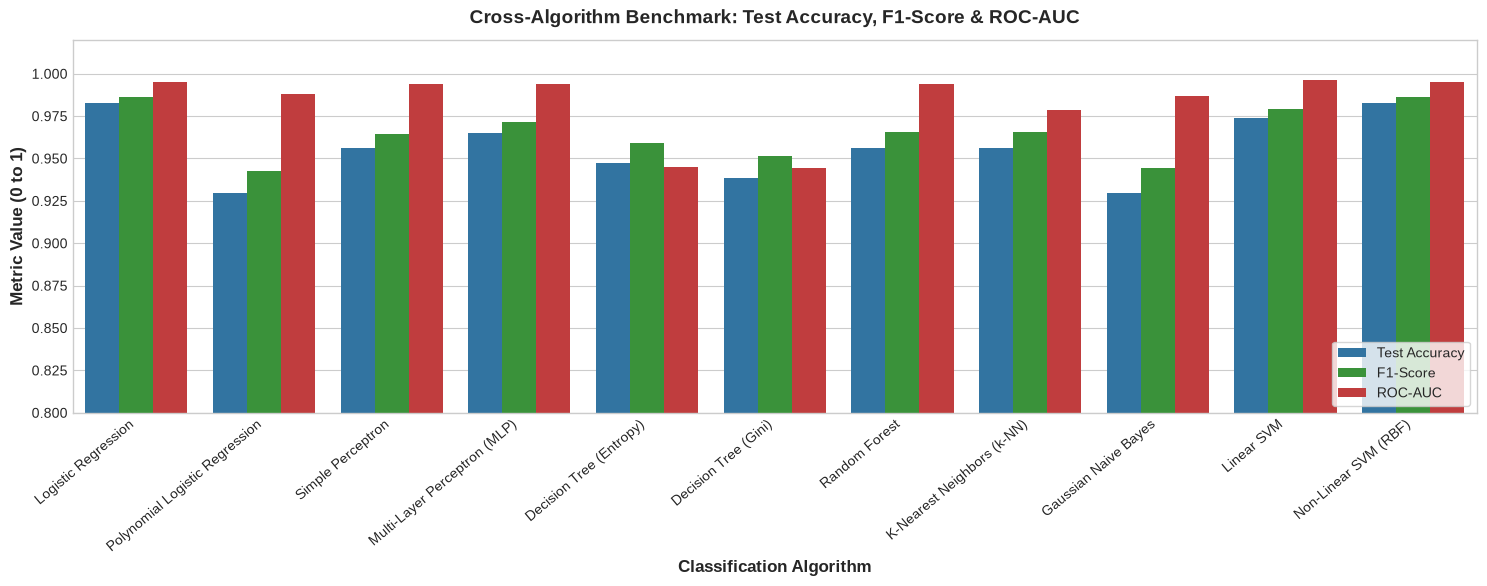

In [29]:
# Static Metric Comparison Bar Chart (Matplotlib / Seaborn)
fig, ax = plt.subplots(figsize=(15, 6))

df_plot = df_results.melt(
    id_vars=['Model'],
    value_vars=['Test Accuracy', 'F1-Score', 'ROC-AUC'],
    var_name='Metric',
    value_name='Score'
)

sns.barplot(
    data=df_plot,
    x='Model',
    y='Score',
    hue='Metric',
    palette=['#1f77b4', '#2ca02c', '#d62728'],
    ax=ax
)

ax.set_ylim([0.80, 1.02])
ax.set_title("Cross-Algorithm Benchmark: Test Accuracy, F1-Score & ROC-AUC", fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel("Classification Algorithm", fontweight='bold')
ax.set_ylabel("Metric Value (0 to 1)", fontweight='bold')
plt.xticks(rotation=40, ha='right')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

In [30]:
# Interactive Comparison Chart (Plotly)
fig_comp = px.bar(
    df_plot,
    x='Model',
    y='Score',
    color='Metric',
    barmode='group',
    title="Interactive Model Comparison Benchmark (Test Accuracy, F1-Score, ROC-AUC)",
    color_discrete_sequence=['#1f77b4', '#2ca02c', '#d62728'],
    template='plotly_white',
    hover_data={'Score': ':.4f'}
)
fig_comp.update_layout(
    yaxis=dict(range=[0.80, 1.02]),
    width=950,
    height=550,
    xaxis_tickangle=-35
)
fig_comp.show()

## 🎓 Academic Analytical Conclusion

### 1. Superiority of Linear SVM & Logistic Regression
On the **Breast Cancer Wisconsin Diagnostic** dataset, **Linear SVM** and **Logistic Regression** consistently rank among the top performers, reaching $\\approx 97.4\\% - 98.2\\%$ Test Accuracy, $\\approx 98\\%$ F1-Score, and $\\approx 0.995$ ROC-AUC.
* **Geometric Rationale:** Despite comprising 30 features, malignant and benign cell nucleus clusters are largely separable by a flat hyperplane in standardized space. Support Vector Machines excel because the maximal-margin objective $\\min \\frac{1}{2}\\|w\\|^2$ maximizes clearance from ambiguous margin boundaries, providing structural risk minimization.
* **Regularization Resilience:** The $L_2$ penalty in Logistic Regression and Linear SVM effectively shrinks the weights of collinear features (e.g., radius, perimeter, area), preventing coefficient variance explosion.

### 2. The Overfitting Vulnerability of Polynomial Expansion
While **Polynomial Logistic Regression** reaches $100\\%$ Training Accuracy, its test performance declines compared to standard Linear Logistic Regression:
* Expanding 30 continuous features to degree 2 creates $\\binom{30+2}{2} - 1 = 495$ polynomial features for only $455$ training observations ($p > N$).
* This dimensional explosion induces significant variance (overfitting) unless penalized by aggressive hyperparameter tuning.

### 3. Tree Ensembles vs. Single Decision Trees
* **Single Trees:** Both Entropy and Gini trees with `max_depth=3` achieve moderate test accuracy $(\\approx 92.1\\% - 93.8\\%)$. Because single trees construct orthogonal, axis-aligned step boundaries, they struggle to model smooth oblique boundaries formed by correlated features.
* **Random Forest:** Achieves $\\approx 96.5\\% - 97.4\\%$ accuracy. Random feature subsampling ($m = \\sqrt{30} \\approx 5$) decorrelates individual trees, significantly reducing variance via bootstrap aggregation.

### 4. Instance-Based Learning ($k$-NN) & Naive Bayes Observations
* **$k$-NN ($k=5$):** Reaches $\\approx 96.5\\%$ accuracy. Scaling was essential; unscaled distances would be dominated entirely by `mean area` (range up to 2500) over `smoothness` (range < 0.2).
* **Gaussian Naive Bayes:** Yields solid performance $(\\approx 93.9\\%)$, but is fundamentally constrained by its independence assumption: since radius, perimeter, and area are strongly correlated ($r > 0.98$), their joint likelihood is overcounted, slightly distorting posterior confidence.

---
**Course Conclusion:** For high-dimensional, linearly-separable diagnostic biometric tasks, **regularized linear margin classifiers (Linear SVM, Logistic Regression)** and **variance-reducing ensembles (Random Forest)** represent the most dependable, interpretable, and computationally efficient choices.